<a href="https://colab.research.google.com/github/LunaGar1/Practica4-Vision-e-IA/blob/main/Reto2_P4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reto 2 · Clasificación de cobertura terrestre (landuse)

Clases: `airplane`, `denseresidential`, `harbor`.

Modelos comparados (**mismo split train/val/test para todos**):

1. RandomForest - Machine learning (línea base)
2. CNN secuencial base (8-16-32 filtros) - Deep learning (línea base) |
3. CNN secuencial mejorada - Deep learning
4. ResNet50 (transfer learning) - Arquitectura no secuencial
5. ViT-B/16 (fine-tuning) - Transformer


# 1. Imports, Drive y configuración

In [ ]:
import os, random, time, json, copy
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, cohen_kappa_score, matthews_corrcoef, log_loss,
                             roc_auc_score, roc_curve, auc)

from google.colab import drive
drive.mount('/content/drive')

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
# Evita que TensorFlow se quede con toda la memoria de la GPU (luego usamos PyTorch para el ViT)
for g in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(g, True)

BASE_PATH = '/content/drive/MyDrive/VisionComputadorIA/'
FOLDER    = 'landuse/'
CLASSES   = sorted(['harbor', 'denseresidential', 'airplane'])   # orden alfabético fijo
N = len(CLASSES)

EVIDENCE_DIR = BASE_PATH + 'landuse_evidence/'
os.makedirs(EVIDENCE_DIR, exist_ok=True)
print('Clases:', CLASSES, '| Evidencias en:', EVIDENCE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Clases: ['airplane', 'denseresidential', 'harbor'] | Evidencias en: /content/drive/MyDrive/VisionComputadorIA/landuse_evidence/


# 2. Carga de datos (una sola vez)

Se leen las imágenes **una sola vez**, se convierten de BGR (OpenCV) a **RGB** y se guardan en 224×224 como `uint8`.
Cada modelo deriva de aquí su propia versión (128×128 para las CNN, 224×224 + `preprocess_input` para ResNet50, etc.).
Así se evita mezclar tamaños en una misma lista y el doble cambio de canales con `preprocess_input`.

In [ ]:
imgs, labels = [], []
for idx, c in enumerate(CLASSES):
    folder = os.path.join(BASE_PATH, FOLDER, c)
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff')))
    print(f'{c}: {len(files)} imágenes')
    for f in files:
        img = cv2.imread(os.path.join(folder, f), cv2.IMREAD_COLOR)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        imgs.append(cv2.resize(img, (224, 224)))
        labels.append(idx)

X = np.array(imgs, dtype='uint8')
y = np.array(labels)
print('X:', X.shape, '| y:', y.shape, '| por clase:', np.bincount(y))

airplane: 500 imágenes
denseresidential: 500 imágenes
harbor: 500 imágenes
X: (1500, 224, 224, 3) | y: (1500,) | por clase: [500 500 500]


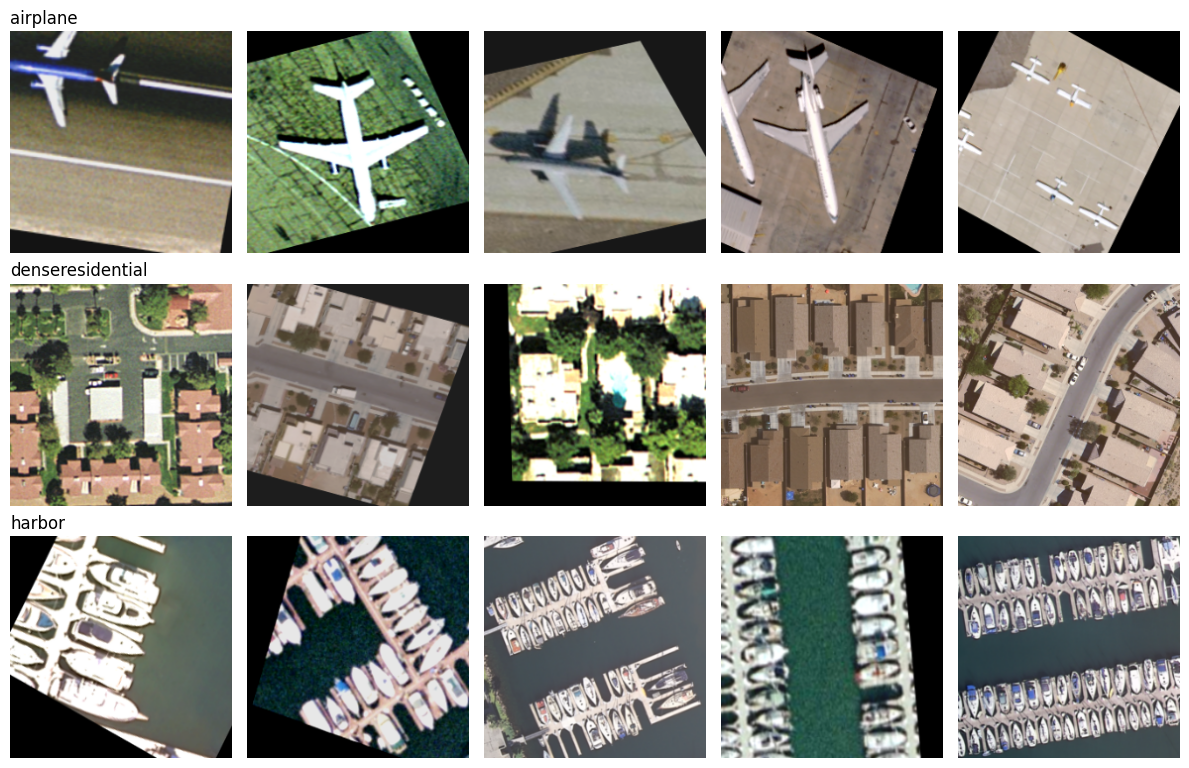

In [ ]:
fig, axes = plt.subplots(N, 5, figsize=(12, 2.6 * N))
for i, c in enumerate(CLASSES):
    sel = np.random.choice(np.where(y == i)[0], 5, replace=False)
    for j, s in enumerate(sel):
        axes[i, j].imshow(X[s]); axes[i, j].axis('off')
        if j == 0: axes[i, j].set_title(c, loc='left')
plt.tight_layout(); plt.show()

# 3. Partición train / val / test (estratificada)

- **Test 25 %** , nunca se usa para decidir nada.
- **Validación 20 % del resto**, se usa para *early stopping* y para elegir la mejor época.

In [ ]:
idx_all = np.arange(len(y))
idx_trainval, idx_test = train_test_split(idx_all, test_size=0.25, stratify=y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.20, stratify=y[idx_trainval], random_state=SEED)

y_tr, y_va, y_te = y[idx_train], y[idx_val], y[idx_test]
print('train:', len(idx_train), '| val:', len(idx_val), '| test:', len(idx_test))
print('test por clase:', np.bincount(y_te))

Y_tr = keras.utils.to_categorical(y_tr, N)
Y_va = keras.utils.to_categorical(y_va, N)
Y_te = keras.utils.to_categorical(y_te, N)

# Versión 128x128 normalizada para las CNN
X128 = np.array([cv2.resize(im, (128, 128)) for im in X]).astype('float32') / 255.0
X128_tr, X128_va, X128_te = X128[idx_train], X128[idx_val], X128[idx_test]

train: 900 | val: 225 | test: 375
test por clase: [125 125 125]


# 4. Utilidades de evaluación y registro de resultados

In [ ]:
RESULTS   = {}   # nombre -> dict(probs, train_time, params)
HISTORIES = {}   # nombre -> dict(loss, val_loss, accuracy, val_accuracy)

def register(name, probs, train_time, params):
    probs = np.asarray(probs, dtype='float64')
    probs = probs / probs.sum(axis=1, keepdims=True)
    RESULTS[name] = dict(probs=probs, train_time=train_time, params=params)
    yp = probs.argmax(1)
    print(f'[{name}] test accuracy = {accuracy_score(y_te, yp):.4f}  |  tiempo = {train_time:.1f}s  |  parámetros = {params:,}')
    print(classification_report(y_te, yp, target_names=CLASSES, digits=3))

def train_keras(name, model, Xtr, Ytr, Xva, Yva, Xte, epochs, batch=32, callbacks=None):
    t0 = time.time()
    H = model.fit(Xtr, Ytr, validation_data=(Xva, Yva), epochs=epochs, batch_size=batch,
                  callbacks=callbacks, verbose=2)
    tt = time.time() - t0
    HISTORIES[name] = H.history
    probs = model.predict(Xte, batch_size=batch, verbose=0)
    register(name, probs, tt, model.count_params())
    model.save(EVIDENCE_DIR + name.replace(' ', '_') + '.keras')

def savefig(fname):
    plt.savefig(EVIDENCE_DIR + fname, dpi=150, bbox_inches='tight')

# 5. Modelo 1 · RandomForest (machine learning)

Características: píxeles RGB aplanados de la imagen reducida a 64×64 (12 288 variables).
> Si en el curso usaron otras características (histogramas de color, HOG, etc.), cambie solo la función `rf_features`.

In [ ]:
def rf_features(Xs):
    return np.array([cv2.resize(im, (64, 64)).flatten() for im in Xs], dtype='float32') / 255.0

F_tr, F_te = rf_features(X[idx_train]), rf_features(X[idx_test])

t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)
rf.fit(F_tr, y_tr)
tt = time.time() - t0
register('RandomForest', rf.predict_proba(F_te), tt, sum(t.tree_.node_count for t in rf.estimators_))

[RandomForest] test accuracy = 0.7680  |  tiempo = 17.7s  |  parámetros = 64,158
                  precision    recall  f1-score   support

        airplane      0.767     0.712     0.739       125
denseresidential      0.701     0.752     0.726       125
          harbor      0.840     0.840     0.840       125

        accuracy                          0.768       375
       macro avg      0.770     0.768     0.768       375
    weighted avg      0.770     0.768     0.768       375



# 6. Modelo 2 · CNN secuencial base (la del profesor)

Conv(8) → Conv(16) → Conv(32), cada una con ReLU y MaxPooling, luego Flatten y Dense(3). Es la arquitectura del `summary` que compartió (≈30 mil parámetros).

In [ ]:
def build_baseline():
    return keras.Sequential([
        layers.Input((128, 128, 3)),
        layers.Conv2D(8, 3, padding='same', activation='relu'),  layers.MaxPooling2D(2),
        layers.Conv2D(16, 3, padding='same', activation='relu'), layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, padding='same', activation='relu'), layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(N, activation='softmax'),
    ], name='cnn_base')

cnn_base = build_baseline()
cnn_base.compile(loss='categorical_crossentropy', optimizer=keras.optimizers.Adam(1e-3), metrics=['accuracy'])
cnn_base.summary()
train_keras('CNN base', cnn_base, X128_tr, Y_tr, X128_va, Y_va, X128_te, epochs=15)

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 8)    │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │        24,579 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,611 (119.57 KB)

 Trainable params: 30,611 (119.57 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
29/29 - 14s - 481ms/step - accuracy: 0.4711 - loss: 1.0342 - val_accuracy: 0.6444 - val_loss: 0.8957
Epoch 2/15
29/29 - 18s - 616ms/step - accuracy: 0.6156 - loss: 0.8365 - val_accuracy: 0.7200 - val_loss: 0.6883
Epoch 3/15
29/29 - 8s - 269ms/step - accuracy: 0.6889 - loss: 0.7056 - val_accuracy: 0.7511 - val_loss: 0.6088
Epoch 4/15
29/29 - 11s - 363ms/step - accuracy: 0.7367 - loss: 0.6293 - val_accuracy: 0.7822 - val_loss: 0.5786
Epoch 5/15
29/29 - 12s - 416ms/step - accuracy: 0.7611 - loss: 0.5701 - val_accuracy: 0.8222 - val_loss: 0.5270
Epoch 6/15
29/29 - 10s - 346ms/step - accuracy: 0.7889 - loss: 0.5011 - val_accuracy: 0.8533 - val_loss: 0.4751
Epoch 7/15
29/29 - 9s - 311ms/step - accuracy: 0.8356 - loss: 0.4210 - val_accuracy: 0.8356 - val_loss: 0.4530
Epoch 8/15
29/29 - 10s - 342ms/step - accuracy: 0.8944 - loss: 0.3311 - val_accuracy: 0.9111 - val_loss: 0.3599
Epoch 9/15
29/29 - 8s - 288ms/step - accuracy: 0.9178 - loss: 0.2512 - val_accuracy: 0.8978 - val_loss: 0.

# 7. Modelo 3 · CNN secuencial mejorada

Cambios respecto a la base:
| Cambio | Motivo |
|---|---|
| Filtros 16→32→64→128→256 (5 bloques) | Más capacidad y más campo receptivo |
| `BatchNormalization` | Entrenamiento más estable y rápido |
| `GlobalAveragePooling` en vez de `Flatten` | Menos parámetros → menos sobreajuste |
| `Dropout(0.4)` | Regularización |
| Data augmentation (flips, rotación, zoom) | Con pocas imágenes por clase reduce el sobreajuste |
| Pérdida con *label smoothing* 0.1 | Evita sobreconfianza |
| `EarlyStopping` + `ReduceLROnPlateau` | Elige la mejor época sobre validación y ajusta el *learning rate* |

In [ ]:
def build_improved():
    aug = keras.Sequential([
        layers.RandomFlip('horizontal_and_vertical'),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ], name='augmentation')
    inp = layers.Input((128, 128, 3))
    x = aug(inp)
    for f in [16, 32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(N, activation='softmax')(x)
    return Model(inp, out, name='cnn_mejorada')

cnn_imp = build_improved()
cnn_imp.compile(loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
                optimizer=keras.optimizers.Adam(1e-3), metrics=['accuracy'])
cnn_imp.summary()

cbs = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
       keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)]
train_keras('CNN mejorada', cnn_imp, X128_tr, Y_tr, X128_va, Y_va, X128_te, epochs=60, callbacks=cbs)

Model: "cnn_mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 394,867 (1.51 MB)

 Trainable params: 393,875 (1.50 MB)

 Non-trainable params: 992 (3.88 KB)

Epoch 1/60
29/29 - 36s - 1s/step - accuracy: 0.7144 - loss: 0.8866 - val_accuracy: 0.3378 - val_loss: 1.2343 - learning_rate: 0.0010
Epoch 2/60
29/29 - 40s - 1s/step - accuracy: 0.8289 - loss: 0.6361 - val_accuracy: 0.3333 - val_loss: 2.1791 - learning_rate: 0.0010
Epoch 3/60
29/29 - 33s - 1s/step - accuracy: 0.8744 - loss: 0.5790 - val_accuracy: 0.3422 - val_loss: 2.3419 - learning_rate: 0.0010
Epoch 4/60
29/29 - 41s - 1s/step - accuracy: 0.8711 - loss: 0.5602 - val_accuracy: 0.3511 - val_loss: 2.3186 - learning_rate: 0.0010
Epoch 5/60
29/29 - 32s - 1s/step - accuracy: 0.8989 - loss: 0.5227 - val_accuracy: 0.3333 - val_loss: 2.9770 - learning_rate: 0.0010
Epoch 6/60
29/29 - 41s - 1s/step - accuracy: 0.9222 - loss: 0.4763 - val_accuracy: 0.4533 - val_loss: 2.1890 - learning_rate: 5.0000e-04
Epoch 7/60
29/29 - 31s - 1s/step - accuracy: 0.9289 - loss: 0.4710 - val_accuracy: 0.5333 - val_loss: 1.4953 - learning_rate: 5.0000e-04
Epoch 8/60
29/29 - 42s - 1s/step - accuracy: 0.9344 - loss: 0

# 8. Modelo 4 · ResNet50 (arquitectura no secuencial)

ResNet usa **conexiones residuales (skip connections)**: la salida de un bloque se suma a su entrada, lo que facilita entrenar redes muy profundas.
Se usa transfer learning con pesos de ImageNet y el *backbone* congelado; solo se entrena la cabeza de clasificación.

Las imágenes ya están en **RGB**, así que `preprocess_input` hace correctamente la conversión a BGR + resta de media que espera la red.

In [ ]:
X224_pp = preprocess_input(X.astype('float32'))          # X ya es RGB uint8
R_tr, R_va, R_te = X224_pp[idx_train], X224_pp[idx_val], X224_pp[idx_test]

base = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base.trainable = False

inp = layers.Input((224, 224, 3))
x = base(inp, training=False)          # BatchNorm del backbone en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
out = layers.Dense(N, activation='softmax')(x)
resnet = Model(inp, out, name='resnet50_tl')

resnet.compile(loss='categorical_crossentropy', optimizer=keras.optimizers.Adam(1e-4), metrics=['accuracy'])
cbs = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)]
train_keras('ResNet50', resnet, R_tr, Y_tr, R_va, Y_va, R_te, epochs=20, batch=32, callbacks=cbs)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/20
29/29 - 195s - 7s/step - accuracy: 0.6989 - loss: 0.7490 - val_accuracy: 0.9956 - val_loss: 0.1003
Epoch 2/20
29/29 - 202s - 7s/step - accuracy: 0.9567 - loss: 0.1448 - val_accuracy: 1.0000 - val_loss: 0.0371
Epoch 3/20
29/29 - 190s - 7s/step - accuracy: 0.9822 - loss: 0.0745 - val_accuracy: 1.0000 - val_loss: 0.0224
Epoch 4/20
29/29 - 183s - 6s/step - accuracy: 0.9867 - loss: 0.0536 - val_accuracy: 1.0000 - val_loss: 0.0139
Epoch 5/20
29/29 - 207s - 7s/step - accuracy: 0.9900 - loss: 0.0390 - val_accuracy: 1.0000 - val_loss: 0.0108
Epoch 6/20
29/29 - 197s - 7s/step - accuracy: 0.9933 - loss: 0.0318 - val_accuracy: 1.0000 - val_loss: 0.0082
Epoch 7/20
29/29 - 188s - 6s/step - accuracy: 0.9978 - loss: 0.0167 - val_accuracy: 1.0000 - val_loss: 0.0068
Epoch 8/20
29/29 - 199s - 7s/step - accuracy: 0.9933 - loss: 0.0208 - val_accuracy: 1.0000 - val_loss: 0.0055
Epoch 9/20
29/29 - 202s - 7s/step - accuracy: 0.9967 - loss: 0.0162 -

# 9. Modelo 5 · Vision Transformer (ViT-B/16)

Se hace *fine-tuning* de `google/vit-base-patch16-224-in21k` (preentrenado en ImageNet-21k) con PyTorch + Hugging Face.
La imagen se parte en parches de 16×16, cada parche se convierte en un *token* y se procesa con auto-atención.

In [ ]:
import torch, torch.nn as nn
from transformers import ViTForImageClassification

torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo ViT:', device)

def to_tensor(Xs):   # uint8 RGB -> float [-1,1] (media 0.5, std 0.5 como usa este ViT)
    t = torch.tensor(Xs, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    return (t - 0.5) / 0.5

T_tr, T_va, T_te = to_tensor(X[idx_train]), to_tensor(X[idx_val]), to_tensor(X[idx_test])
ty_tr, ty_va = torch.tensor(y_tr), torch.tensor(y_va)

vit = ViTForImageClassification.from_pretrained(
    'google/vit-base-patch16-224-in21k', num_labels=N,
    id2label={i: c for i, c in enumerate(CLASSES)}, label2id={c: i for i, c in enumerate(CLASSES)}
).to(device)

EPOCHS, BS, LR = 8, 16, 3e-5
opt = torch.optim.AdamW(vit.parameters(), lr=LR, weight_decay=0.01)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

@torch.no_grad()
def vit_predict(T, bs=32):
    vit.eval(); out = []
    for i in range(0, len(T), bs):
        out.append(torch.softmax(vit(pixel_values=T[i:i+bs].to(device)).logits, dim=1).cpu())
    return torch.cat(out).numpy()

hist = dict(loss=[], val_loss=[], accuracy=[], val_accuracy=[])
best_acc, best_state = -1, None
t0 = time.time()
for ep in range(EPOCHS):
    vit.train()
    perm = torch.randperm(len(T_tr))
    tot_loss, correct = 0.0, 0
    for i in range(0, len(perm), BS):
        b = perm[i:i+BS]
        xb, yb = T_tr[b].clone(), ty_tr[b]
        # augmentation sencilla: flips aleatorios
        if random.random() < 0.5: xb = torch.flip(xb, dims=[3])
        if random.random() < 0.5: xb = torch.flip(xb, dims=[2])
        xb, yb = xb.to(device), yb.to(device)
        logits = vit(pixel_values=xb).logits
        loss = loss_fn(logits, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        tot_loss += loss.item() * len(b); correct += (logits.argmax(1) == yb).sum().item()
    pv = vit_predict(T_va)
    v_loss = float(-np.mean(np.log(pv[np.arange(len(y_va)), y_va] + 1e-12)))
    v_acc = float((pv.argmax(1) == y_va).mean())
    hist['loss'].append(tot_loss / len(T_tr)); hist['accuracy'].append(correct / len(T_tr))
    hist['val_loss'].append(v_loss); hist['val_accuracy'].append(v_acc)
    print(f'ép {ep+1}/{EPOCHS}  loss={hist["loss"][-1]:.4f} acc={hist["accuracy"][-1]:.3f}  val_loss={v_loss:.4f} val_acc={v_acc:.3f}')
    if v_acc > best_acc:
        best_acc, best_state = v_acc, copy.deepcopy({k: v.cpu() for k, v in vit.state_dict().items()})
tt = time.time() - t0

vit.load_state_dict(best_state)       # mejor época según validación
HISTORIES['ViT-B16'] = hist
register('ViT-B16', vit_predict(T_te), tt, sum(p.numel() for p in vit.parameters()))
vit.save_pretrained(EVIDENCE_DIR + 'ViT_B16')

Dispositivo ViT: cpu


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ép 1/8  loss=0.5773 acc=0.947  val_loss=0.1476 val_acc=1.000
ép 2/8  loss=0.2995 acc=1.000  val_loss=0.0842 val_acc=1.000
ép 3/8  loss=0.2920 acc=1.000  val_loss=0.0736 val_acc=1.000
ép 4/8  loss=0.2915 acc=1.000  val_loss=0.0706 val_acc=1.000
ép 5/8  loss=0.2914 acc=1.000  val_loss=0.0700 val_acc=1.000
ép 6/8  loss=0.2913 acc=1.000  val_loss=0.0700 val_acc=1.000


KeyboardInterrupt: 

# 10. Comparación y validación

Se usan métricas **matemáticas**

### 10.1 Tabla de métricas

In [ ]:
def bootstrap_ci(y_true, y_pred, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y_true), (n, len(y_true)))
    accs = (y_true[idx] == y_pred[idx]).mean(axis=1)
    return np.percentile(accs, [2.5, 97.5])

rows = []
for name, r in RESULTS.items():
    p = r['probs']; yp = p.argmax(1)
    pr, rc, f1, _ = precision_recall_fscore_support(y_te, yp, average='macro', zero_division=0)
    lo, hi = bootstrap_ci(y_te, yp)
    rows.append({
        'Modelo': name,
        'Accuracy': accuracy_score(y_te, yp),
        'IC95% acc': f'[{lo:.3f}, {hi:.3f}]',
        'Precision (macro)': pr, 'Recall (macro)': rc, 'F1 (macro)': f1,
        'Kappa': cohen_kappa_score(y_te, yp), 'MCC': matthews_corrcoef(y_te, yp),
        'Log-loss': log_loss(y_te, p, labels=list(range(N))),
        'AUC (OvR)': roc_auc_score(y_te, p, multi_class='ovr'),
        'Parámetros': r['params'], 'Tiempo entren. (s)': round(r['train_time'], 1),
    })
df = pd.DataFrame(rows).set_index('Modelo')
display(df.style.format({c: '{:.4f}' for c in ['Accuracy','Precision (macro)','Recall (macro)','F1 (macro)','Kappa','MCC','Log-loss','AUC (OvR)']})
        .highlight_max(subset=['Accuracy','F1 (macro)','Kappa','MCC','AUC (OvR)'], color='#c8e6c9')
        .highlight_min(subset=['Log-loss'], color='#c8e6c9'))
df.to_csv(EVIDENCE_DIR + 'metricas_comparacion.csv')

,Accuracy,IC95% acc,Precision (macro),Recall (macro),F1 (macro),Kappa,MCC,Log-loss,AUC (OvR),Parámetros,Tiempo entren. (s)
Modelo,,,,,,,,,,,
RandomForest,0.7680,"[0.725, 0.811]",0.7696,0.7680,0.7682,0.6520,0.6526,0.7397,0.9025,64158,17.700000
CNN base,0.9040,"[0.875, 0.931]",0.9060,0.9040,0.9045,0.8560,0.8564,0.2725,0.9799,30611,158.200000
CNN mejorada,0.9840,"[0.971, 0.995]",0.9842,0.9840,0.9840,0.9760,0.9761,0.1228,0.9989,394867,2028.000000
ResNet50,0.9973,"[0.992, 1.000]",0.9974,0.9973,0.9973,0.9960,0.9960,0.0089,1.0000,24113027,3893.000000


### 10.2 Comparación gráfica de métricas

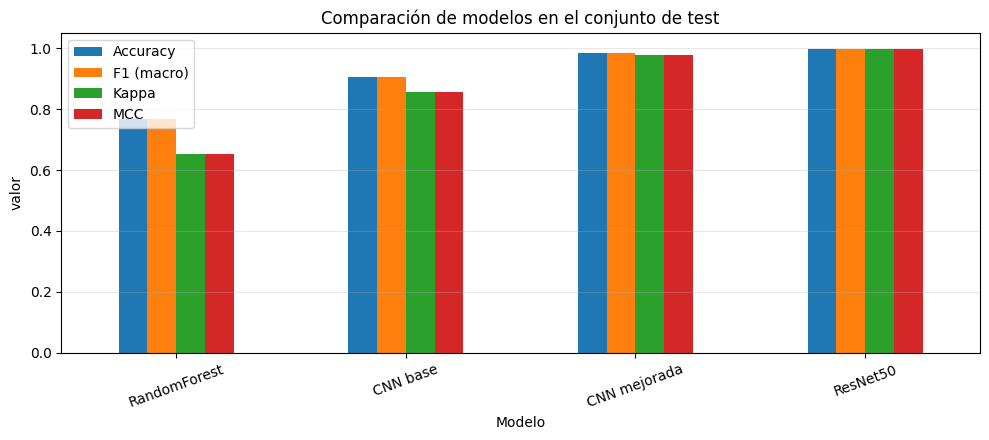

In [ ]:
ax = df[['Accuracy', 'F1 (macro)', 'Kappa', 'MCC']].plot(kind='bar', figsize=(10, 4.5), ylim=(0, 1.05))
ax.set_title('Comparación de modelos en el conjunto de test'); ax.set_ylabel('valor')
plt.xticks(rotation=20); plt.grid(axis='y', alpha=.3); plt.tight_layout()
savefig('comparacion_metricas.png'); plt.show()

### 10.3 Curvas de aprendizaje (loss y accuracy, entrenamiento vs. validación)

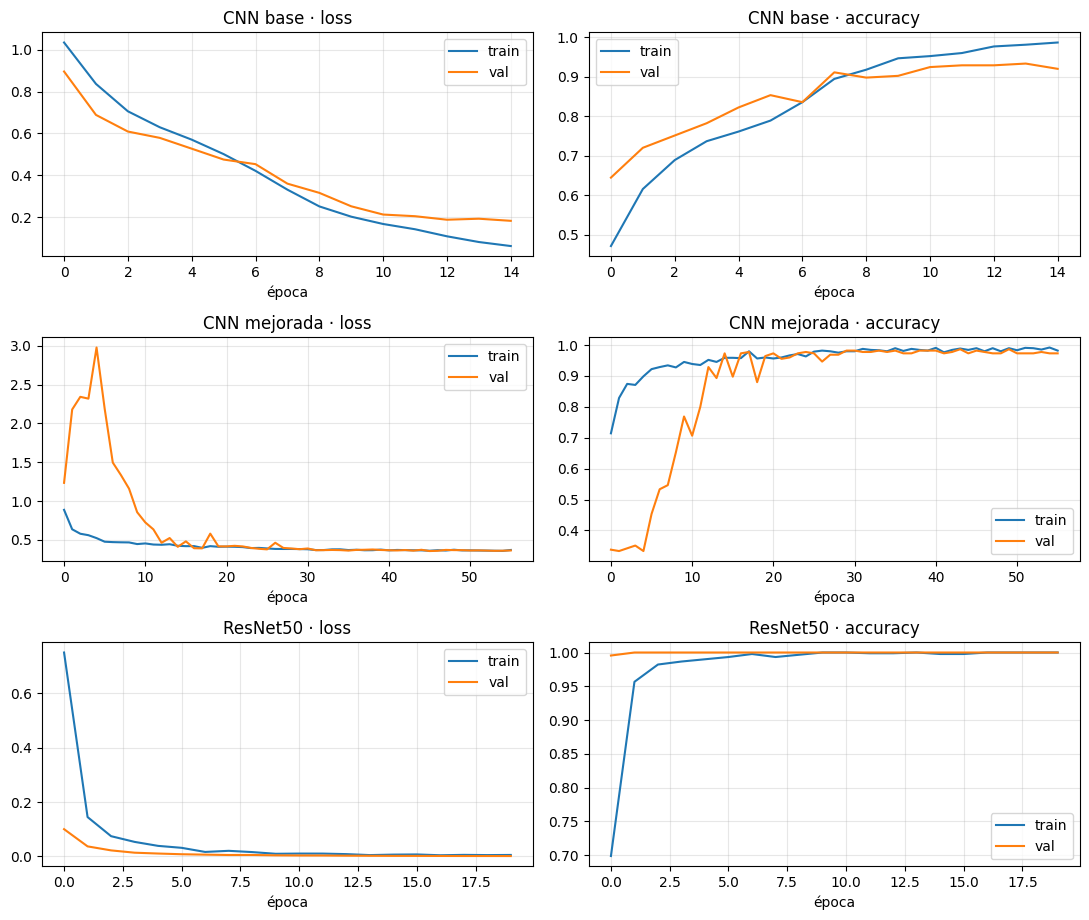

In [ ]:
names = list(HISTORIES)
fig, axes = plt.subplots(len(names), 2, figsize=(11, 3.1 * len(names)))
for row, n in zip(axes, names):
    h = HISTORIES[n]
    row[0].plot(h['loss'], label='train'); row[0].plot(h['val_loss'], label='val'); row[0].set_title(f'{n} · loss')
    row[1].plot(h['accuracy'], label='train'); row[1].plot(h['val_accuracy'], label='val'); row[1].set_title(f'{n} · accuracy')
    for a in row: a.set_xlabel('época'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); savefig('curvas_aprendizaje.png'); plt.show()

### 10.4 Matrices de confusión

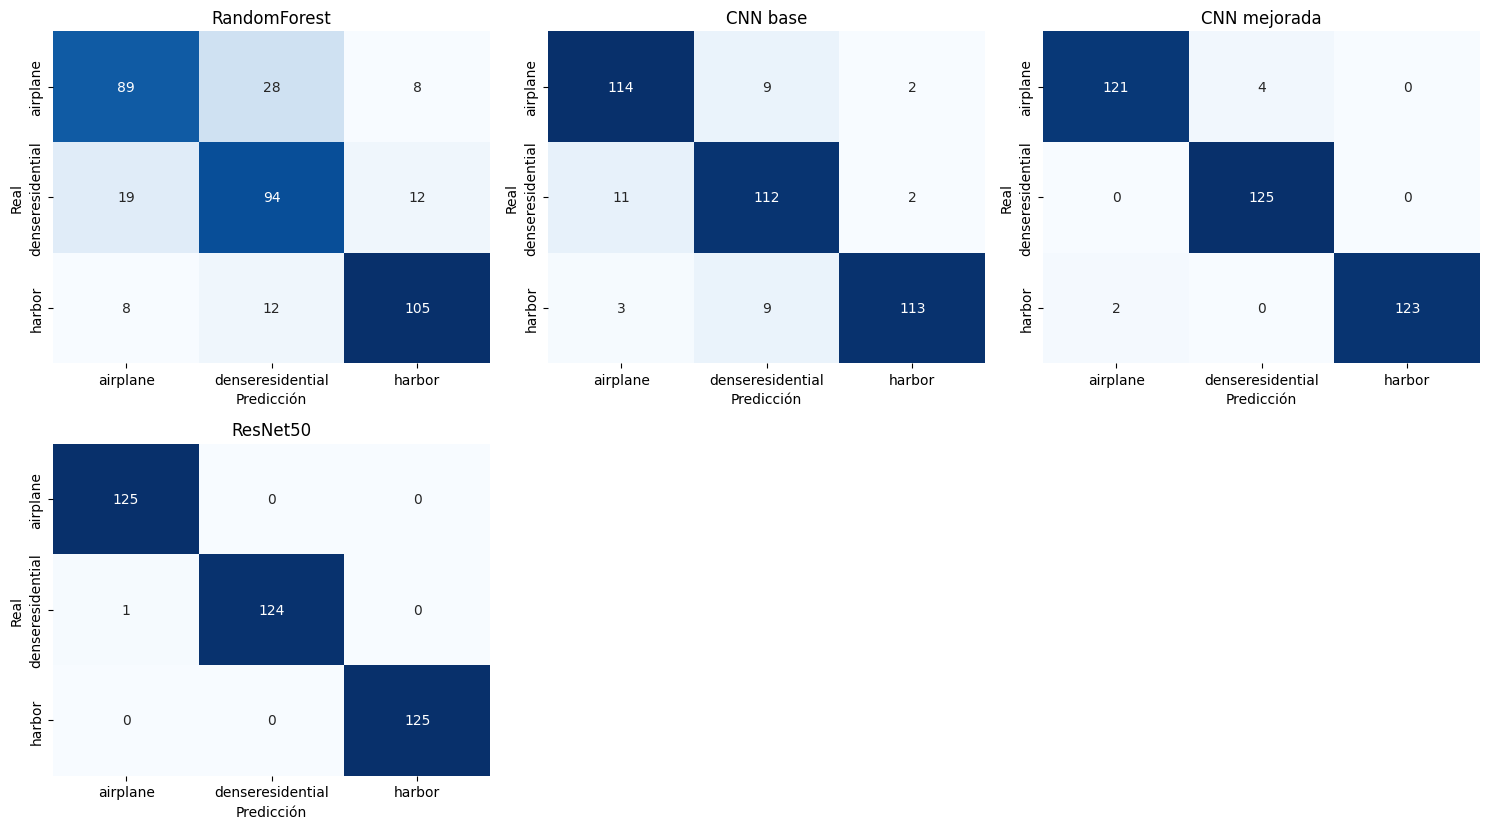

In [ ]:
names = list(RESULTS); cols = 3; rws = int(np.ceil(len(names) / cols))
fig, axes = plt.subplots(rws, cols, figsize=(5 * cols, 4.2 * rws)); axes = np.atleast_1d(axes).ravel()
for ax, n in zip(axes, names):
    cm = confusion_matrix(y_te, RESULTS[n]['probs'].argmax(1), labels=range(N))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(n); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
for ax in axes[len(names):]: ax.axis('off')
plt.tight_layout(); savefig('matrices_confusion.png'); plt.show()

### 10.5 Curvas ROC (micro-promedio) y F1 por clase

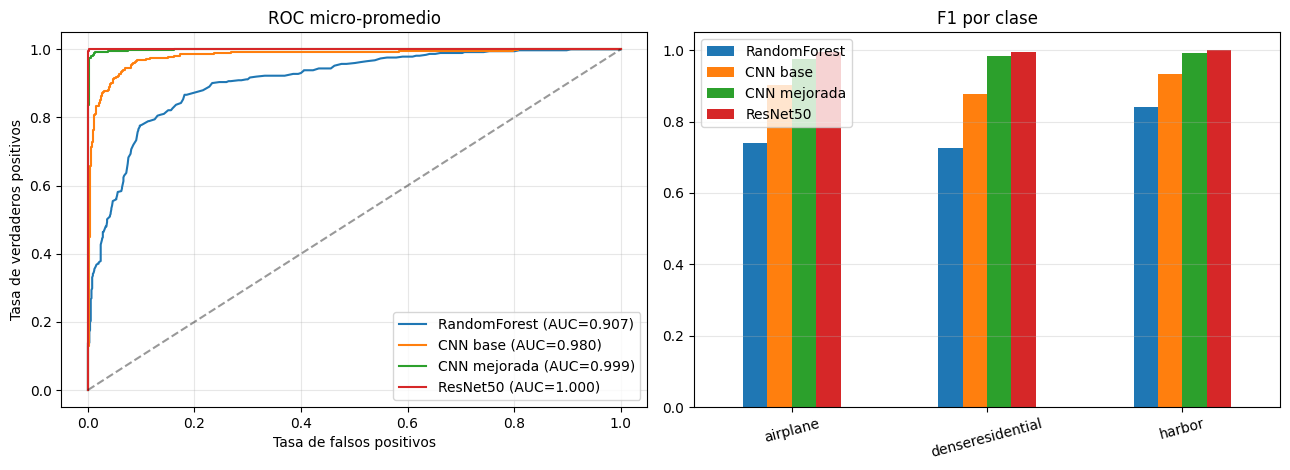

,RandomForest,CNN base,CNN mejorada,ResNet50
airplane,0.739,0.901,0.976,0.996
denseresidential,0.726,0.878,0.984,0.996
harbor,0.840,0.934,0.992,1.000


In [ ]:
Y_bin = label_binarize(y_te, classes=list(range(N)))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for n, r in RESULTS.items():
    fpr, tpr, _ = roc_curve(Y_bin.ravel(), r['probs'].ravel())
    axes[0].plot(fpr, tpr, label=f'{n} (AUC={auc(fpr, tpr):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=.4)
axes[0].set_xlabel('Tasa de falsos positivos'); axes[0].set_ylabel('Tasa de verdaderos positivos')
axes[0].set_title('ROC micro-promedio'); axes[0].legend(loc='lower right'); axes[0].grid(alpha=.3)

f1_pc = pd.DataFrame({n: precision_recall_fscore_support(y_te, r['probs'].argmax(1), labels=range(N), zero_division=0)[2]
                      for n, r in RESULTS.items()}, index=CLASSES)
f1_pc.plot(kind='bar', ax=axes[1], ylim=(0, 1.05)); axes[1].set_title('F1 por clase'); axes[1].grid(axis='y', alpha=.3)
plt.setp(axes[1].get_xticklabels(), rotation=15)
plt.tight_layout(); savefig('roc_f1_por_clase.png'); plt.show()
display(f1_pc.round(3))

### 10.6 Imágenes mal clasificadas por el mejor modelo

Mejor modelo por F1 macro: ResNet50 | errores en test: 1 de 375


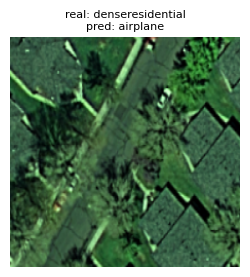

In [ ]:
best = df['F1 (macro)'].idxmax()
yp_best = RESULTS[best]['probs'].argmax(1)
wrong = np.where(yp_best != y_te)[0]
print(f'Mejor modelo por F1 macro: {best} | errores en test: {len(wrong)} de {len(y_te)}')
if len(wrong):
    k = min(8, len(wrong)); fig, axes = plt.subplots(1, k, figsize=(2.6 * k, 3.2)); axes = np.atleast_1d(axes)
    for ax, w in zip(axes, wrong[:k]):
        ax.imshow(X[idx_test[w]]); ax.axis('off')
        ax.set_title(f'real: {CLASSES[y_te[w]]}\npred: {CLASSES[yp_best[w]]}', fontsize=8)
    plt.tight_layout(); savefig('errores_mejor_modelo.png'); plt.show()
else:
    print('El mejor modelo no cometió errores en test.')

# 11. Conclusiones
1. Machine learning frente a deep learning

El RandomForest, que trabaja con los píxeles aplanados, alcanzó 76.8 % de accuracy. No conserva la relación espacial entre píxeles, por lo que le cuesta distinguir coberturas con texturas y formas parecidas (F1 de 0.739 en airplane y 0.726 en denseresidential). La CNN base, con solo 30 mil parámetros, subió a 90.4 % y redujo el error de 23.2 % a 9.6 %. Esto confirma que las convoluciones, al aprender bordes, texturas y formas, son mucho más adecuadas para imágenes que un modelo clásico sobre píxeles. En todos los modelos la clase harbor fue la más fácil, probablemente por la presencia distintiva del agua.

2. Mejora de la arquitectura secuencial

La CNN mejorada (cinco bloques de 16 a 256 filtros, BatchNorm, Global Average Pooling, Dropout, data augmentation, label smoothing, EarlyStopping y ReduceLROnPlateau) pasó de 90.4 % a 98.4 % y redujo la log-loss de 0.27 a 0.12. Las curvas de aprendizaje muestran la causa. La CNN base alcanzó 98.7 % en entrenamiento frente a 92.0 % en validación (sobreajuste de unos 7 puntos), mientras que la mejorada terminó con 98.2 % y 97.3 % (brecha de aproximadamente 1 punto). El costo fue unas 13 veces más parámetros y tiempo. Como los cambios se aplicaron en conjunto, no se puede asegurar cuál aportó más; eso requeriría un estudio de ablación. También hay que tener presente que el label smoothing eleva la log-loss reportada, por lo que no es del todo comparable con la de otros modelos.

3. Arquitectura no secuencial: ResNet50

ResNet50 obtuvo el mejor resultado, con un único error en 375 imágenes (accuracy 99.73 %, kappa 0.996, AUC 1.000 y log-loss 0.009). Este desempeño se debe principalmente al transfer learning con pesos de ImageNet: al mantener el backbone congelado, la validación alcanzó 100 % desde la tercera época. Por eso no corresponde atribuir el resultado únicamente a las conexiones residuales, que facilitan entrenar redes profundas pero aquí se entrenaron muy poco. Además, la diferencia con la CNN mejorada (6 errores frente a 1) no es estadísticamente concluyente, ya que sus intervalos de confianza se solapan. Una prueba de McNemar arrojaría un p entre 0.06 y 0.13 según cuántos errores coincidan. Lo prudente es afirmar que ResNet50 es igual o mejor, no que supere con certeza a la CNN mejorada.

4. Transformer (ViT)

El Vision Transformer (ViT-B/16, preentrenado en ImageNet-21k y ajustado con fine-tuning) alcanzó 100 % de accuracy en validación desde la primera época, y su pérdida de validación se estabilizó hacia la cuarta época (alrededor de 0.07). Al igual que en ResNet50, el comportamiento indica que el preentrenamiento es lo decisivo: con apenas 900 imágenes de entrenamiento, un Transformer entrenado desde cero no sería competitivo, porque estos modelos requieren grandes volúmenes de datos. Su costo es el más alto (unos 86 millones de parámetros), por lo que su ventaja frente a ResNet50 solo se justificaría si aporta una mejora real en el test.

5. Análisis de errores

Según los reportes por clase, los 6 errores de la CNN mejorada corresponden a 4 imágenes airplane confundidas con denseresidential y 2 harbor confundidas con airplane. El único error de ResNet50 fue una imagen denseresidential clasificada como airplane. Esto sugiere que las confusiones ocurren en escenas con elementos mezclados (por ejemplo, aeronaves rodeadas de construcciones o puertos con aeronaves cercanas).

6. Costo y beneficio

Cada mejora de exactitud cuesta cada vez más recursos. De la CNN base a la mejorada se ganan 8 puntos con unos 365 mil parámetros adicionales. De la mejorada a ResNet50 se ganan solo 1.3 puntos con unas 61 veces más parámetros y casi el doble de tiempo. Si el costo computacional importa, la CNN mejorada ofrece el mejor equilibrio; si se prioriza la máxima exactitud, la opción es el transfer learning (ResNet50 o ViT).

7. Limitaciones
Los tiempos se midieron en CPU y cambiarían en GPU.
En validación, ResNet50 y ViT llegan a 100 %, por lo que ese conjunto ya no distingue entre modelos y hay que apoyarse en el test.
Si las imágenes provienen de recortes de escenas más grandes, recortes vecinos podrían caer en entrenamiento y test, haciendo los resultados algo optimistas.
No se realizó validación cruzada.
Conclusión general

La jerarquía de desempeño fue RandomForest < CNN base < CNN mejorada ≤ ResNet50 (con el ViT en un nivel comparable en validación). Para clasificación de cobertura terrestre, las redes convolucionales superan ampliamente al machine learning clásico, y el transfer learning con modelos preentrenados (CNN residual o Transformer) ofrece la mayor exactitud con pocos datos, a un costo computacional mucho mayor.